In [1]:
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import eu9_osm
from shapely.geometry import Point

In [2]:
# Lisbon airport
lat, lon = 38.7742, -9.1342
center = (lat, lon)
radius = 3500
crs = "EPSG:3763"

In [3]:
# OSM data
buildings = eu9_osm.features_from_point(center, {"building": True}, dist=radius, shape="box").to_crs(crs)
roads = eu9_osm.features_from_point(center, {"highway": True}, dist=radius, shape="box").to_crs(crs)
parks = eu9_osm.features_from_point(center, {"leisure": ["park", "garden"]}, dist=radius, shape="box").to_crs(crs)
airport_data = eu9_osm.features_from_point(center, {"aeroway": "aerodrome"}, dist=radius, shape="box").to_crs(crs)
runways = eu9_osm.features_from_point(center, {"aeroway": "runway"}, dist=radius, shape="box").to_crs(crs)
taxiways = eu9_osm.features_from_point(center, {"aeroway": "taxiway"}, dist=radius, shape="box").to_crs(crs)

In [4]:
# Relevant geomteries
buildings = buildings[buildings.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]
roads = roads[roads.geometry.geom_type.isin(["LineString", "MultiLineString"])]
parks = parks[parks.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]
airport_data = airport_data[airport_data.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]
runway_lines = runways[runways.geometry.geom_type.isin(["LineString", "MultiLineString"])]
taxiway_lines = taxiways[taxiways.geometry.geom_type.isin(["LineString", "MultiLineString"])]

In [5]:
# Metric coords
airport_center = gpd.GeoSeries([Point(lon, lat)], crs="EPSG:4326").to_crs(crs).iloc[0]
# Poly closest to the centre
airport_index = airport_data.geometry.distance(airport_center).idxmin()
airport = airport_data.loc[airport_index, "geometry"]
# Map limits
minx, miny, maxx, maxy = airport.bounds

In [6]:
# Tree params
tree_spacing = 25
runway_offset = 45
taxiway_offset = 15

# Create trees
trees = []

for lines, offset in [(runway_lines, runway_offset), (taxiway_lines, taxiway_offset)]:

    for geometry in lines.geometry:        
        if geometry.geom_type == "LineString":
            parts = [geometry]
        else:
            parts = list(geometry.geoms)

        for line in parts:
            # Parallel sides
            for side in ["left", "right"]:
                parallel = line.parallel_offset(offset, side)
                
                if parallel.geom_type == "LineString":
                    parallel_parts = [parallel]

                elif parallel.geom_type == "MultiLineString":
                    parallel_parts = list(parallel.geoms)

                else:
                    continue

                for parallel_line in parallel_parts:                    
                    for distance in np.arange(0, parallel_line.length, tree_spacing):
                        tree = parallel_line.interpolate(distance)

                        # Only trees inside the airport
                        if airport.covers(tree):
                            trees.append(tree)

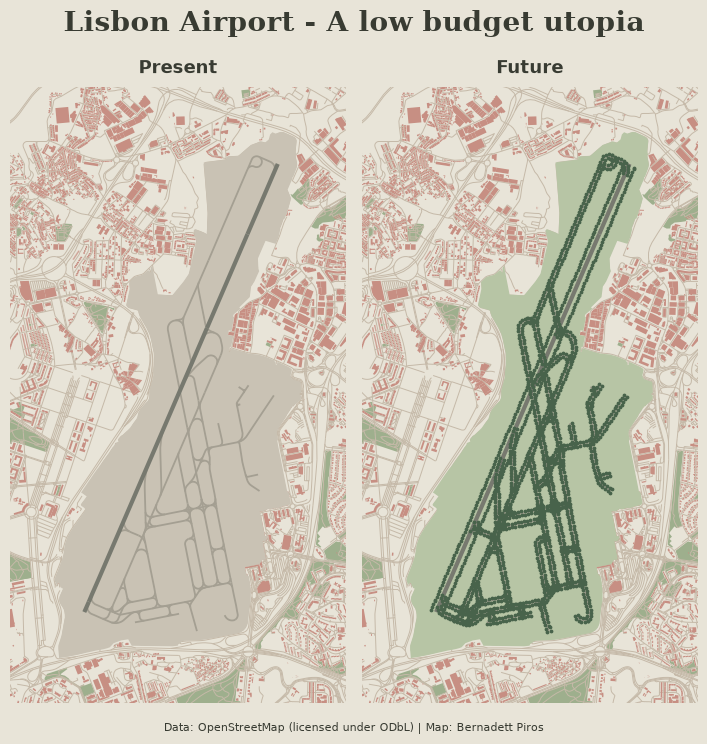

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 8), facecolor="#E8E4D8")

# City
for ax in axes:
    ax.set_facecolor("#E8E4D8")
    parks.plot(ax=ax, color="#9EAF8D", zorder=1)
    roads.plot(ax=ax, color="#C5B9A8", linewidth=0.7, zorder=2)
    buildings.plot(ax=ax, color="#C78F83", edgecolor="none", zorder=3)

# Airport
for ax, color in zip(axes, ["#C9C2B4", "#B7C5A5"]):
    # Airport bg
    gpd.GeoSeries([airport], crs=crs).plot(ax=ax, color=color, zorder=4)
    # Taxiways
    taxiways.plot(ax=ax, color="#A49F92", linewidth=1.3, zorder=5)
    # Runways
    runways.plot(ax=ax, color="#77796F", linewidth=3, zorder=6)

# Trees
axes[1].scatter([tree.x for tree in trees], [tree.y for tree in trees], s=3, color="#48634B", zorder=7)

# Titles & aesthetics
titles = ["Present", "Future"]

padding = 350

for ax, title in zip(axes, titles):

    ax.set_xlim(minx - padding, maxx + padding)
    ax.set_ylim(miny - padding, maxy + padding)    

    ax.set_aspect("equal")
    ax.axis("off")

    ax.set_title(title, color="#383B32", size=13, weight="bold", pad=10)

fig.text(0.5, 0.95,
    "Lisbon Airport - A low budget utopia",    
     color="#383B32", size=20, weight="bold", fontfamily="serif", ha="center")

fig.text(0.5, 0.075,
         "Data: OpenStreetMap (licensed under ODbL) | Map: Bernadett Piros",
         color="#383B32", size=8, ha="center")         

plt.subplots_adjust(left=0.15, right=0.85, wspace=0.01)

plt.show()

# Save image
#plt.savefig("low_cost.png", bbox_inches="tight", pad_inches=0.2)